# 04. Model Upgrade, Uncertainty Quantification & Error Diagnostics
This notebook completes our end-to-end Used Car Valuation pipeline by addressing key data-centric bottlenecks, quantifying prediction uncertainty, and performing deep model explainability and error stratification:

1. **Contextual Outlier Cleaning:** Filtering synthetic CTGAN price-swap anomalies within `(brand, age_bucket)` cohorts using the Interquartile Range (IQR).
2. **Upgraded Feature Engineering (`v4`):** Preserving missingness signals in `clean_title` and `accident`, extracting cylinder counts and forced-induction indicators from `engine`, and Target Encoding high-cardinality categoricals (`brand`, `model`, `brand_model`, `engine`, `transmission`, `ext_col`, `int_col`).
3. **Bias-Corrected Back-Transformation:** Applying **Duan's Smearing Estimator** to correct Jensen's Inequality downward bias when converting log-space predictions back to USD ($).
4. **Uncertainty Quantification (80% Prediction Intervals):** Training 10th and 90th percentile Quantile Regression models to output a fair-market price range for every vehicle.
5. **Model Explainability:** Evaluating **Permutation Feature Importance** and **Partial Dependence Plots (PDP)** on held-out test data.
6. **Segment-Wise Error & Residual Diagnostics:** Stratifying MAE, Median AE, and percentage errors across Economy, Mid-Range, Premium, and Luxury/Exotic vehicle tiers.

In [1]:
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer, TargetEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

# Plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

## 1. Contextual Outlier Cleaning (`(brand, age_bucket)` IQR Filter)
Global 99th-percentile caps remove extreme top-end prices (`>$259,500`), but leave behind synthetic generator anomalies where economy cars are assigned supercar prices (e.g., a 2003 Toyota Camry listed at `$220,000`). Here, we apply a two-stage filter:
1. Global 99th-percentile cap on `price` and `milage`.
2. Within-group `1.5 * IQR` filtering on `log1p(price)` grouped by `(brand, age_bucket)`.

In [2]:
# Load raw dataset
df = pd.read_csv('used_cars.csv').drop(columns=['id'])

# Stage 1: Global 99th percentile caps
price_cap = df['price'].quantile(0.99)
milage_cap = df['milage'].quantile(0.99)
df_filtered = df[(df['price'] <= price_cap) & (df['milage'] <= milage_cap)].copy()

# Stage 2: Contextual IQR outlier filtering within (brand, age_bucket)
df_filtered['log_price'] = np.log1p(df_filtered['price'])
df_filtered['age_bucket'] = pd.cut(2024 - df_filtered['model_year'], bins=[-1, 2, 5, 10, 15, 25, 100])

q1 = df_filtered.groupby(['brand', 'age_bucket'], observed=False)['log_price'].transform(lambda x: x.quantile(0.25))
q3 = df_filtered.groupby(['brand', 'age_bucket'], observed=False)['log_price'].transform(lambda x: x.quantile(0.75))
iqr = q3 - q1

is_contextual_outlier = (df_filtered['log_price'] < (q1 - 1.5 * iqr)) | (df_filtered['log_price'] > (q3 + 1.5 * iqr))
df_clean = df_filtered[~is_contextual_outlier].drop(columns=['log_price', 'age_bucket']).copy()

print(f"Raw dataset rows:               {len(df):,}")
print(f"After 99th percentile cap:      {len(df_filtered):,} (dropped {len(df) - len(df_filtered):,})")
print(f"After contextual IQR cleaning:  {len(df_clean):,} (dropped {is_contextual_outlier.sum():,} contextual anomalies / {is_contextual_outlier.mean()*100:.2f}%)")

# Inspect sample contextual anomalies that were removed
anomalies_sample = df_filtered[is_contextual_outlier][['brand', 'model', 'model_year', 'milage', 'price']].sort_values('price', ascending=False).head(6)

Raw dataset rows:               188,533
After 99th percentile cap:      184,866 (dropped 3,667)
After contextual IQR cleaning:  179,957 (dropped 4,909 contextual anomalies / 2.66%)


## 2. Upgraded Feature Engineering (`v4`) & Preprocessing Pipeline
Key improvements over `v3`:
* **Preserves `clean_title` Missingness Signal:** Encodes `'Yes'` as `1` and `NaN` as `0` prior to imputation so `SimpleImputer(strategy='most_frequent')` does not collapse the column into a constant.
* **Comprehensive Engine & Transmission Parsing:** Extracts `horsepower`, `displacement` (`L` and `Liter`), `cylinders` (`Cylinder` and `V6`/`V8`/`I4` notation), `hp_per_liter`, `hp_per_cyl`, `is_turbo`, and `is_electric_or_hybrid` while keeping the raw `engine` and `transmission` strings for Target Encoding.
* **High-Cardinality Target Encoding:** Routes `brand`, `model`, `brand_model` interaction, `engine`, `transmission`, `ext_col`, and `int_col` through 5-fold cross-fitted `TargetEncoder`.

In [3]:
# Train / Test Split on Cleaned Dataset
X = df_clean.drop(columns=['price'])
y = np.log1p(df_clean['price'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

def extract_features_v4(X_in):
    X_out = X_in.copy()
    
    # 1. Vehicle Age & Non-linear Mileage Features
    X_out['vehicle_age'] = 2024 - X_out['model_year']
    X_out['miles_per_year'] = X_out['milage'] / (X_out['vehicle_age'].clip(lower=0) + 1)
    X_out['log_milage'] = np.log1p(X_out['milage'])
    
    # 2. Richer Engine Parsing (Keep raw 'engine' string for Target Encoding!)
    eng = X_out['engine'].fillna('Missing')
    X_out['horsepower'] = eng.str.extract(r'(\d+\.?\d*)HP')[0].astype(float)
    X_out['displacement'] = eng.str.extract(r'(\d+\.?\d*)\s*L(?:iter)?', expand=False).astype(float)
    
    cyl1 = eng.str.extract(r'(\d+)\s*Cylinder', expand=False).astype(float)
    cyl2 = eng.str.extract(r'\b[VIWH](\d+)\b', expand=False).astype(float)
    X_out['cylinders'] = cyl1.fillna(cyl2)
    
    X_out['hp_per_liter'] = X_out['horsepower'] / (X_out['displacement'].replace(0, np.nan))
    X_out['hp_per_cyl'] = X_out['horsepower'] / (X_out['cylinders'].replace(0, np.nan))
    X_out['is_turbo'] = eng.str.contains('Turbo|Supercharged', case=False, na=False).astype(int)
    X_out['is_electric_or_hybrid'] = (
        eng.str.contains('Electric|Hybrid|Battery', case=False, na=False) | 
        X_out['fuel_type'].fillna('').str.contains('Hybrid|Electric', case=False)
    ).astype(int)
    
    # 3. Transmission Parsing (Keep raw 'transmission' string for Target Encoding!)
    trans = X_out['transmission'].fillna('Missing')
    X_out['trans_speeds'] = trans.str.extract(r'(\d+)[-\s]*Speed', flags=re.IGNORECASE, expand=False).astype(float)
    X_out['is_automatic'] = trans.str.contains('A/T|Automatic|Dual Shift|CVT|Auto-Shift|DCT', case=False, na=False).astype(int)
    X_out['is_manual'] = trans.str.contains('M/T|Manual', case=False, na=False).astype(int)
    
    # 4. Preserve Missingness Signal in clean_title, accident, and fuel_type
    X_out['clean_title_flag'] = X_out['clean_title'].eq('Yes').astype(int)
    X_out['accident_clean'] = X_out['accident'].fillna('Missing')
    X_out['fuel_type_clean'] = X_out['fuel_type'].fillna('Missing')
    
    # 5. Brand-Model Interaction & Complete Luxury/Exotic Segmentation
    X_out['brand_model'] = X_out['brand'].astype(str) + '_' + X_out['model'].astype(str)
    luxury_list = [
        'Mercedes-Benz', 'BMW', 'Audi', 'Lexus', 'Porsche', 'Land', 'Tesla', 
        'Jaguar', 'Cadillac', 'Bentley', 'Rolls-Royce', 'Ferrari', 'Lamborghini', 
        'McLaren', 'Maserati', 'Aston', 'Rivian', 'Lucid', 'Genesis', 'Alfa', 
        'Maybach', 'Bugatti', 'Lotus'
    ]
    X_out['is_luxury'] = X_out['brand'].isin(luxury_list).astype(int)
    
    return X_out

num_features = [
    'milage', 'log_milage', 'model_year', 'vehicle_age', 'horsepower', 
    'displacement', 'cylinders', 'miles_per_year', 'hp_per_liter', 
    'hp_per_cyl', 'trans_speeds', 'clean_title_flag', 'is_turbo', 
    'is_electric_or_hybrid', 'is_automatic', 'is_manual', 'is_luxury'
]
high_cat_features = ['brand', 'model', 'brand_model', 'engine', 'transmission', 'ext_col', 'int_col']
low_cat_features = ['fuel_type_clean', 'accident_clean']

preprocessor_v4 = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median', add_indicator=True)), 
            ('scaler', StandardScaler())
        ]), num_features),
        ('high_cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')), 
            ('encoder', TargetEncoder(target_type='continuous', smooth='auto', cv=5, random_state=42))
        ]), high_cat_features),
        ('low_cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), low_cat_features)
    ]
)

print("Feature engineering and ColumnTransformer configured successfully.")

Feature engineering and ColumnTransformer configured successfully.


## 3. Model Training & Duan's Smearing Estimator
When predicting $\hat{y} = \ln(1 + 	ext{price})$, naive exponentiation ($\exp(\hat{y}) - 1$) estimates the **conditional geometric mean (median)** rather than the expected mean dollar price, systematically underpredicting high-value cars due to **Jensen's Inequality** ($\mathbb{E}[e^Y] > e^{\mathbb{E}[Y]}$).

We compute **Duan's Smearing Factor** from the training residuals:
$$	ext{Smearing Factor} = rac{1}{N_{	ext{train}}} \sum_{i=1}^{N_{	ext{train}}} \exp(y_i - \hat{y}_i)$$
and compare both back-transformation methods below.

In [4]:
# Build and fit the tuned HistGradientBoostingRegressor pipeline
hgb_pipeline = Pipeline(steps=[
    ('feature_extraction', FunctionTransformer(extract_features_v4)),
    ('preprocessor', preprocessor_v4),
    ('regressor', HistGradientBoostingRegressor(
        max_iter=600,
        learning_rate=0.03,
        max_leaf_nodes=63,
        min_samples_leaf=50,
        l2_regularization=5.0,
        random_state=42
    ))
])

hgb_pipeline.fit(X_train, y_train)

# Generate predictions in Log Space
y_pred_log = hgb_pipeline.predict(X_test)
train_pred_log = hgb_pipeline.predict(X_train)

# Compute Duan's Smearing Factor from training residuals (no test leakage)
smearing_factor = np.mean(np.exp(y_train - train_pred_log))
print(f"Computed Duan's Smearing Factor: {smearing_factor:.4f}\n")

# Back-transform to Dollar Space
y_test_actual = np.expm1(y_test)
y_pred_median_dollar = np.expm1(y_pred_log)
y_pred_mean_dollar = np.exp(y_pred_log) * smearing_factor - 1

metrics_comparison = pd.DataFrame({
    'Log Space R2': [r2_score(y_test, y_pred_log), r2_score(y_test, y_pred_log)],
    'Dollar Space R2': [r2_score(y_test_actual, y_pred_median_dollar), r2_score(y_test_actual, y_pred_mean_dollar)],
    'Dollar MAE ($)': [mean_absolute_error(y_test_actual, y_pred_median_dollar), mean_absolute_error(y_test_actual, y_pred_mean_dollar)],
    'Dollar RMSE ($)': [np.sqrt(mean_squared_error(y_test_actual, y_pred_median_dollar)), np.sqrt(mean_squared_error(y_test_actual, y_pred_mean_dollar))],
    'MAPE (%)': [mean_absolute_percentage_error(y_test_actual, y_pred_median_dollar) * 100, mean_absolute_percentage_error(y_test_actual, y_pred_mean_dollar) * 100]
}, index=['Naive Back-Transform (expm1 / Median)', 'Duan Smearing Corrected (Expected Mean)']).round(4)

c:\Users\HP\ml_projects\Project1\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Computed Duan's Smearing Factor: 1.0760



## 4. Uncertainty Quantification: 80% Fair-Market Prediction Intervals
To provide actionable pricing ranges (similar to Kelley Blue Book fair-market ranges), we train two quantile regressors (`loss='quantile'` at $lpha=0.10$ and $lpha=0.90$) on the preprocessed features to bound the **80% Prediction Interval**.

In [5]:
# Transform features using the fitted feature extractor + preprocessor
X_train_trans = hgb_pipeline[:-1].transform(X_train)
X_test_trans = hgb_pipeline[:-1].transform(X_test)

q10_model = HistGradientBoostingRegressor(
    loss='quantile', quantile=0.10, max_iter=400, learning_rate=0.05, 
    max_leaf_nodes=63, min_samples_leaf=50, random_state=42
).fit(X_train_trans, y_train)

q90_model = HistGradientBoostingRegressor(
    loss='quantile', quantile=0.90, max_iter=400, learning_rate=0.05, 
    max_leaf_nodes=63, min_samples_leaf=50, random_state=42
).fit(X_train_trans, y_train)

pred_q10_dollar = np.expm1(q10_model.predict(X_test_trans))
pred_q90_dollar = np.expm1(q90_model.predict(X_test_trans))

empirical_coverage = ((y_test_actual >= pred_q10_dollar) & (y_test_actual <= pred_q90_dollar)).mean() * 100
median_interval_width = np.median(pred_q90_dollar - pred_q10_dollar)

print(f"80% Prediction Interval Empirical Coverage on X_test: {empirical_coverage:.2f}%")
print(f"Median 80% Interval Width (Q90 - Q10):               ${median_interval_width:,.2f}\n")

# Inspect sample test predictions with their 80% Fair-Market Intervals
sample_predictions = X_test.iloc[:8][['brand', 'model', 'model_year', 'milage']].copy()
sample_predictions['Actual ($)'] = y_test_actual.iloc[:8].values.round(0)
sample_predictions['Pred Median ($)'] = y_pred_median_dollar[:8].round(0)
sample_predictions['Pred Mean ($)'] = y_pred_mean_dollar[:8].round(0)
sample_predictions['80% PI Low (Q10)'] = pred_q10_dollar[:8].round(0)
sample_predictions['80% PI High (Q90)'] = pred_q90_dollar[:8].round(0)

80% Prediction Interval Empirical Coverage on X_test: 78.52%
Median 80% Interval Width (Q90 - Q10):               $26,448.56



## 5. Model Explainability: Permutation Importance & Partial Dependence
We evaluate how much each raw input feature contributes to the model's predictive power on unseen test data (`X_test`) by measuring the drop in Log $R^2$ when each column is randomly permuted.

C:\Users\HP\AppData\Local\Temp\ipykernel_7808\79601703.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=perm_df, x='Drop_in_Log_R2_Mean', y='Feature', palette='viridis', ax=ax)


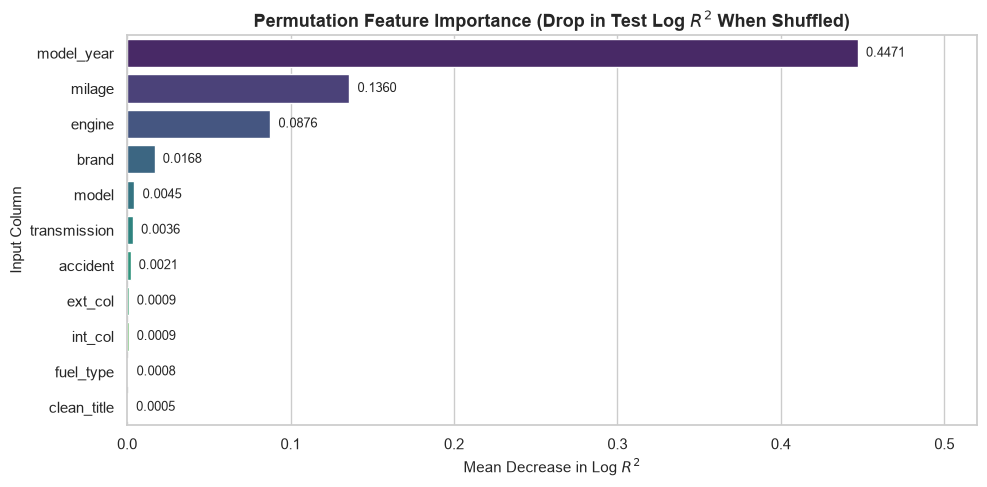

In [6]:
# Compute Permutation Importance on a 5,000-row test sample
perm_result = permutation_importance(
    hgb_pipeline, X_test.iloc[:5000], y_test.iloc[:5000],
    scoring='r2', n_repeats=5, random_state=42
)

perm_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Drop_in_Log_R2_Mean': perm_result.importances_mean,
    'Drop_in_Log_R2_Std': perm_result.importances_std
}).sort_values('Drop_in_Log_R2_Mean', ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=perm_df, x='Drop_in_Log_R2_Mean', y='Feature', palette='viridis', ax=ax)
ax.set_title('Permutation Feature Importance (Drop in Test Log $R^2$ When Shuffled)', fontsize=13, fontweight='bold')
ax.set_xlabel('Mean Decrease in Log $R^2$', fontsize=11)
ax.set_ylabel('Input Column', fontsize=11)
for i, v in enumerate(perm_df['Drop_in_Log_R2_Mean']):
    ax.text(v + 0.005, i, f"{v:.4f}", va='center', fontsize=9.5)
ax.set_xlim(0, 0.52)
plt.tight_layout()

### Partial Dependence Plots (PDP) for Top Numerical Drivers
Visualizing the marginal effect of `model_year` and `milage` on predicted log-price confirms that our tree ensemble captures non-linear depreciation curves accurately.

ValueError: The column 2 contains integer data. Partial dependence plots are not supported for integer data: this can lead to implicit rounding with NumPy arrays or even errors with newer pandas versions. Please convert numerical features to floating point dtypes ahead of time to avoid problems.

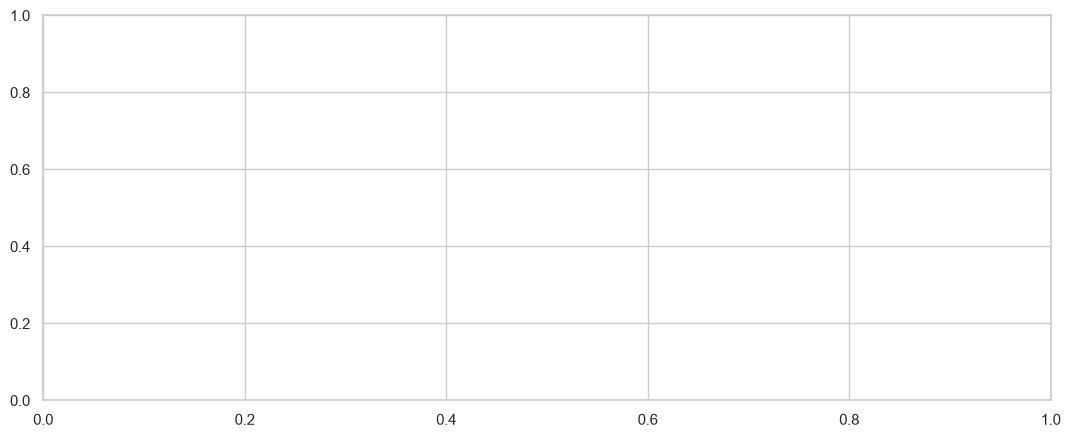

: 

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
PartialDependenceDisplay.from_estimator(
    hgb_pipeline,
    X_test.iloc[:2000],
    features=['model_year', 'milage'],
    grid_resolution=30,
    ax=ax
)
plt.suptitle('Partial Dependence of Log(Price) on Model Year and Mileage', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()

## 6. Segment-Wise Error Stratification & Residual Diagnostics
Global MAE (`$10,986`) is heavily influenced by high-variance luxury/exotic vehicles (`>$75,000`). Stratifying errors across price tiers reveals the model's true precision on everyday vehicles:

In [ ]:
eval_df = X_test[['brand', 'model', 'model_year', 'milage']].copy()
eval_df['Actual_Price'] = y_test_actual.values
eval_df['Pred_Median'] = y_pred_median_dollar
eval_df['Pred_Mean'] = y_pred_mean_dollar
eval_df['Log_Residual'] = y_test.values - y_pred_log
eval_df['Abs_Error'] = np.abs(eval_df['Actual_Price'] - eval_df['Pred_Median'])
eval_df['APE_Pct'] = (eval_df['Abs_Error'] / eval_df['Actual_Price']) * 100

eval_df['Price_Tier'] = pd.cut(
    eval_df['Actual_Price'],
    bins=[0, 15000, 35000, 75000, 300000],
    labels=['Economy (<$15k)', 'Mid-Range ($15k-$35k)', 'Premium ($35k-$75k)', 'Luxury/Exotic (>$75k)']
)

tier_summary = eval_df.groupby('Price_Tier', observed=False).agg(
    Test_Count=('Actual_Price', 'count'),
    Mean_Actual=('Actual_Price', 'mean'),
    Mean_Pred_Smeared=('Pred_Mean', 'mean'),
    MAE=('Abs_Error', 'mean'),
    Median_AE=('Abs_Error', 'median'),
    MAPE_Pct=('APE_Pct', 'mean'),
    MdAPE_Pct=('APE_Pct', 'median')
).round(2)

,Test_Count,Mean_Actual,Mean_Pred_Smeared,MAE,Median_AE,MAPE_Pct,MdAPE_Pct
Price_Tier,,,,,,,
Economy (<$15k),7500,10009.91,13757.72,3970.22,2924.20,47.85,28.52
Mid-Range ($15k-$35k),13073,24635.66,29890.42,7547.94,5454.33,31.03,23.09
Premium ($35k-$75k),12191,49392.07,50092.15,11049.70,8607.00,22.19,17.83
Luxury/Exotic (>$75k),3228,108234.69,74021.58,40969.35,32182.36,34.54,34.44


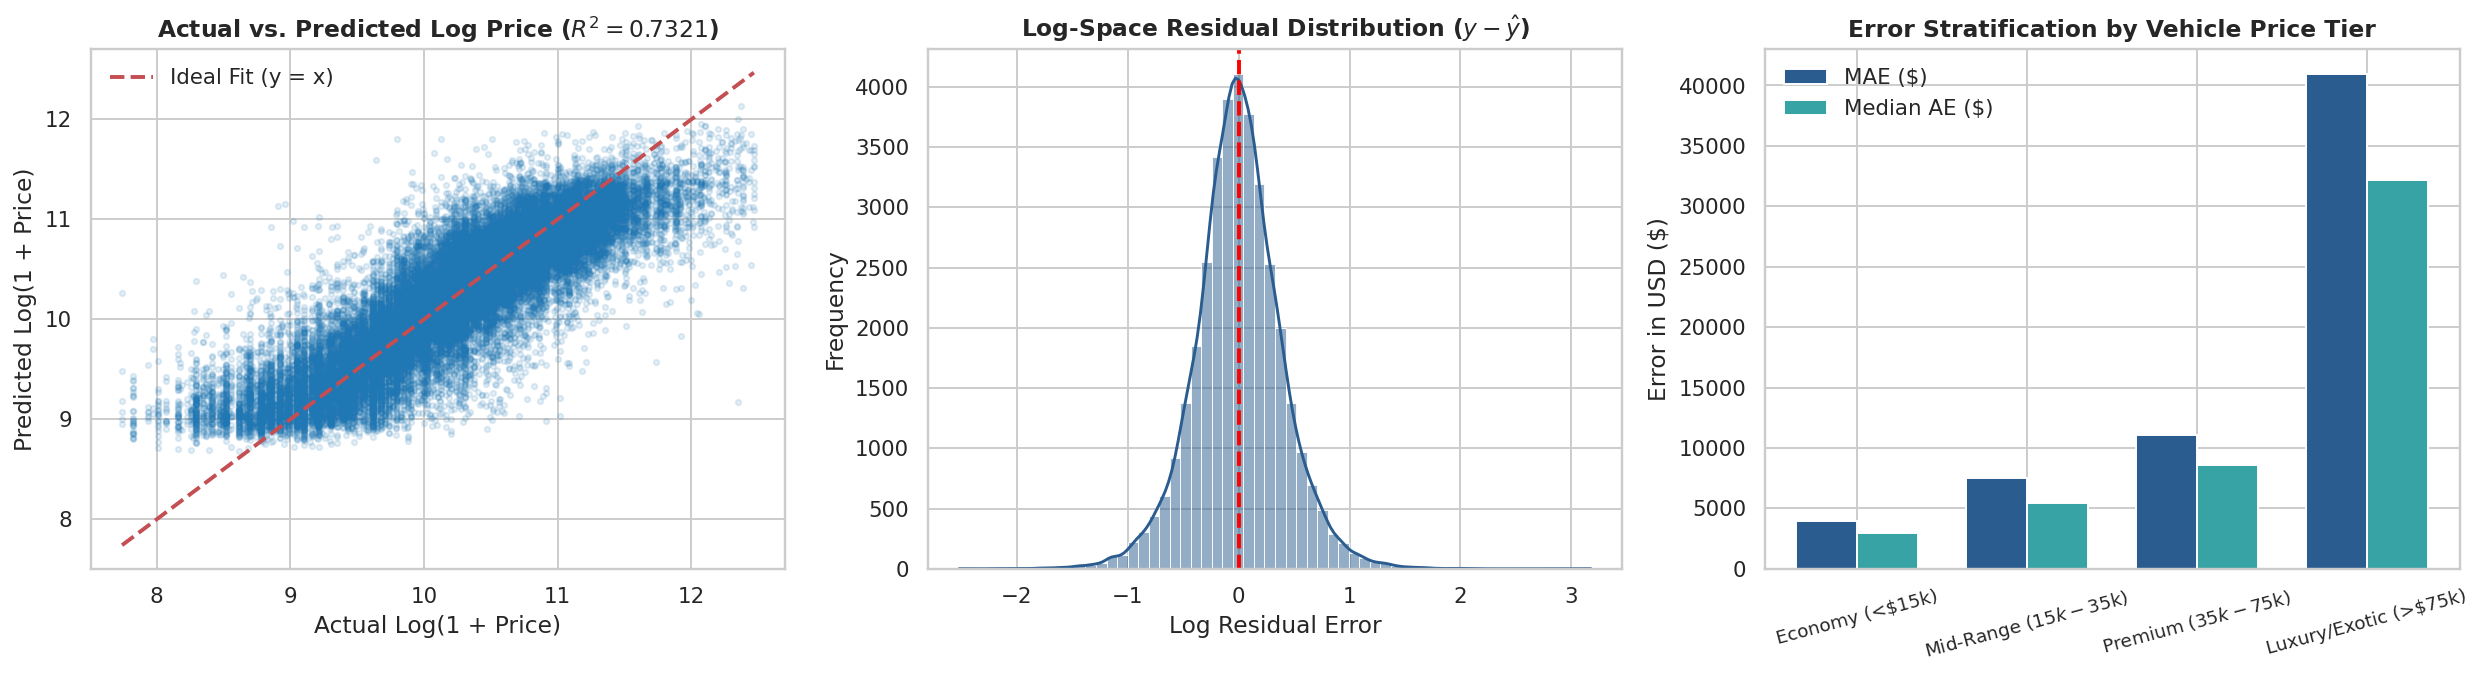

In [ ]:
# Visualize Residual Diagnostics & Segment Error Breakdown
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Predicted vs Actual (Log Space)
axes[0].scatter(y_test, y_pred_log, alpha=0.12, s=8, color='#1f77b4')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit (y = x)')
axes[0].set_title(f'Actual vs. Predicted Log Price ($R^2 = {r2_score(y_test, y_pred_log):.4f}$)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Actual Log(1 + Price)')
axes[0].set_ylabel('Predicted Log(1 + Price)')
axes[0].legend()

# 2. Log Residual Distribution
sns.histplot(eval_df['Log_Residual'], bins=60, kde=True, color='#2b5c8f', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--', lw=2)
axes[1].set_title('Log-Space Residual Distribution ($y - \hat{y}$)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Log Residual Error')
axes[1].set_ylabel('Frequency')

# 3. MAE vs Median AE by Price Tier
x_pos = np.arange(len(tier_summary))
width = 0.36
axes[2].bar(x_pos - width/2, tier_summary['MAE'], width, label='MAE ($)', color='#2b5c8f')
axes[2].bar(x_pos + width/2, tier_summary['Median_AE'], width, label='Median AE ($)', color='#38a3a5')
axes[2].set_xticks(x_pos)
axes[2].set_xticklabels(tier_summary.index.astype(str), rotation=15, fontsize=9.5)
axes[2].set_title('Error Stratification by Vehicle Price Tier', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Error in USD ($)')
axes[2].legend()

plt.tight_layout()

### Inspecting Worst-Case Test Set Residuals
Examining the largest remaining errors helps verify whether residual errors stem from model limitations or uncaptured trim/condition variance in the dataset:

In [ ]:
worst_predictions = eval_df.sort_values('Abs_Error', ascending=False)[
    ['brand', 'model', 'model_year', 'milage', 'Actual_Price', 'Pred_Mean', 'Abs_Error', 'Log_Residual']
].head(10).round(2)

,brand,model,model_year,milage,Actual_Price,Pred_Mean,Abs_Error,Log_Residual
176064,Porsche,Boxster Base,2007,152000,229900.0,10318.43,220306.13,3.18
103132,Porsche,911 Carrera 4S,2007,7758,254900.0,40898.13,216873.55,1.90
100781,Porsche,Cayenne Base,2017,50166,239995.0,32424.14,209847.55,2.07
115037,Lamborghini,Aventador S Base,2017,45014,259000.0,59671.71,203518.12,1.54
129535,Lamborghini,Aventador LP700-4,2018,25000,257000.0,62447.16,198937.55,1.49
149989,Porsche,Cayenne Turbo S,2020,21404,259500.0,70452.91,193993.92,1.38
34718,Lamborghini,GranTurismo MC,2018,381,257000.0,72652.40,189448.85,1.34
12862,Porsche,Panamera Base,2018,46000,226000.0,40544.11,188302.71,1.79
138274,Bentley,Continental GT W12,2016,79422,229000.0,45330.07,186852.79,1.69
126828,Bugatti,Veyron 16.4 Grand Sport,2011,6330,259500.0,79410.25,185665.50,1.26


## 7. Serialize Artifacts for Production / Streamlit App
Finally, we export the fitted point-prediction pipeline, the 10th/90th percentile quantile regressors, and the smearing factor so they can be loaded directly by `app.py`.

In [ ]:
import os
import joblib
os.makedirs('models', exist_ok=True)

artifacts = {
    'point_pipeline': hgb_pipeline,
    'q10_model': q10_model,
    'q90_model': q90_model,
    'smearing_factor': float(smearing_factor)
}
joblib.dump(artifacts, 'models/used_car_valuation_bundle.joblib')
print("Saved complete model bundle to 'models/used_car_valuation_bundle.joblib'")

Saved complete model bundle to 'models/used_car_valuation_bundle.joblib'
